# Nhiệm vụ 1.1: Phân tích Phân phối Sản phẩm, Thị phần Thương hiệu & Nguồn bán

**Thành viên thực hiện**: TV3 (Exploratory Data Analysis)

**Tập dữ liệu đầu vào**: `data/processed/products_processed.jsonl` (10.316 listing, 30 thuộc tính chuẩn hóa)

**Mục tiêu**:
1. Khám phá cơ cấu dữ liệu theo 5 nguồn cào (`source`) và 2 ngành hàng (`category`: Laptop & Smartphone).
2. Phân tích thị phần các thương hiệu hàng đầu (`brand_norm`) toàn thị trường và so sánh đối đầu giữa Laptop và Smartphone.
3. Đánh giá mức độ tập trung của các nhà bán lẻ (`seller_raw`).

In [1]:
import os
import sys
from pathlib import Path

# Tự động định vị REPO_ROOT (chứa data/processed) và đưa working directory về root
curr = Path.cwd().resolve()
while curr != curr.parent:
    if (curr / "data" / "processed" / "products_processed.jsonl").exists():
        os.chdir(curr)
        break
    curr = curr.parent

if "src/eda/scripts" not in sys.path:
    sys.path.insert(0, "src/eda/scripts")

import sys
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Import các module EDA chuẩn hóa

from eda_stats import (
    load_processed_products,
    get_source_category_crosstab,
    get_brand_market_share,
    get_seller_distribution
)
from eda_viz import (
    set_plotting_theme,
    plot_source_category_distribution,
    plot_brand_market_share_comparison,
    plot_seller_share
)

set_plotting_theme()
print("Môi trường phân tích sẵn sàng!")

Môi trường phân tích sẵn sàng!


## 1. Tải dữ liệu và kiểm tra quy mô quan sát

In [2]:
DATA_PATH = "data/processed/products_processed.jsonl"
df = load_processed_products(DATA_PATH)
print(f"Tổng số quan sát listing: {len(df):,}")
print(f"Số lượng thuộc tính: {df.shape[1]}")
df[["listing_record_id", "product_name", "source", "category", "brand_norm", "price_vnd"]].head()

Tổng số quan sát listing: 10,316
Số lượng thuộc tính: 30


,listing_record_id,product_name,source,category,brand_norm,price_vnd
0,4e75c81db2000b7c9e046c8a70f390620546b023e3a39e...,Laptop Dell Inspiron 15 3576 (70157552),cellphones,laptop,Dell,0.0
1,1d86cfa96168e0182a5cebdf47a0479edcc3367cde1a04...,Laptop Acer Aspire Go 15 AG15-72P-54GY,cellphones,laptop,Acer,19990000.0
2,07c0f8731f7dc05c56cc58a9411995c8fdd4546348cc8b...,Laptop Lenovo Gaming Legion 5 15ARH05 82B500GUVN,cellphones,laptop,Lenovo,23190000.0
3,34d2e480532364997896714bd684fa9ee4567afc469fef...,Laptop Gaming Acer Nitro V ANV15-51-57B2,cellphones,laptop,Acer,23290000.0
4,ee8dce31081688722bba31e3a57b54ab0d3d279ec03104...,Laptop Lenovo IdeaPad Slim 5 14Q8X9 83HL000KVN,cellphones,laptop,Lenovo,18490000.0


## 2. Phân bố sản phẩm theo Nguồn bán (Source) và Ngành hàng (Category)

In [3]:
ct_counts, ct_pct = get_source_category_crosstab(df)
print("--- Số lượng quan sát theo Source x Category ---")
display(ct_counts)

print("\n--- Tỷ trọng % so với toàn bộ thị trường ---")
display(ct_pct)

--- Số lượng quan sát theo Source x Category ---


category,laptop,smartphone,Total
source,,,
cellphones,3912,3935,7847
fptshop,356,464,820
hoanghamobile,93,192,285
tgdd,490,707,1197
viettelstore,23,144,167
Total,4874,5442,10316



--- Tỷ trọng % so với toàn bộ thị trường ---


category,laptop,smartphone,Total
source,,,
cellphones,37.92,38.14,76.07
fptshop,3.45,4.50,7.95
hoanghamobile,0.90,1.86,2.76
tgdd,4.75,6.85,11.60
viettelstore,0.22,1.40,1.62
Total,47.25,52.75,100.00


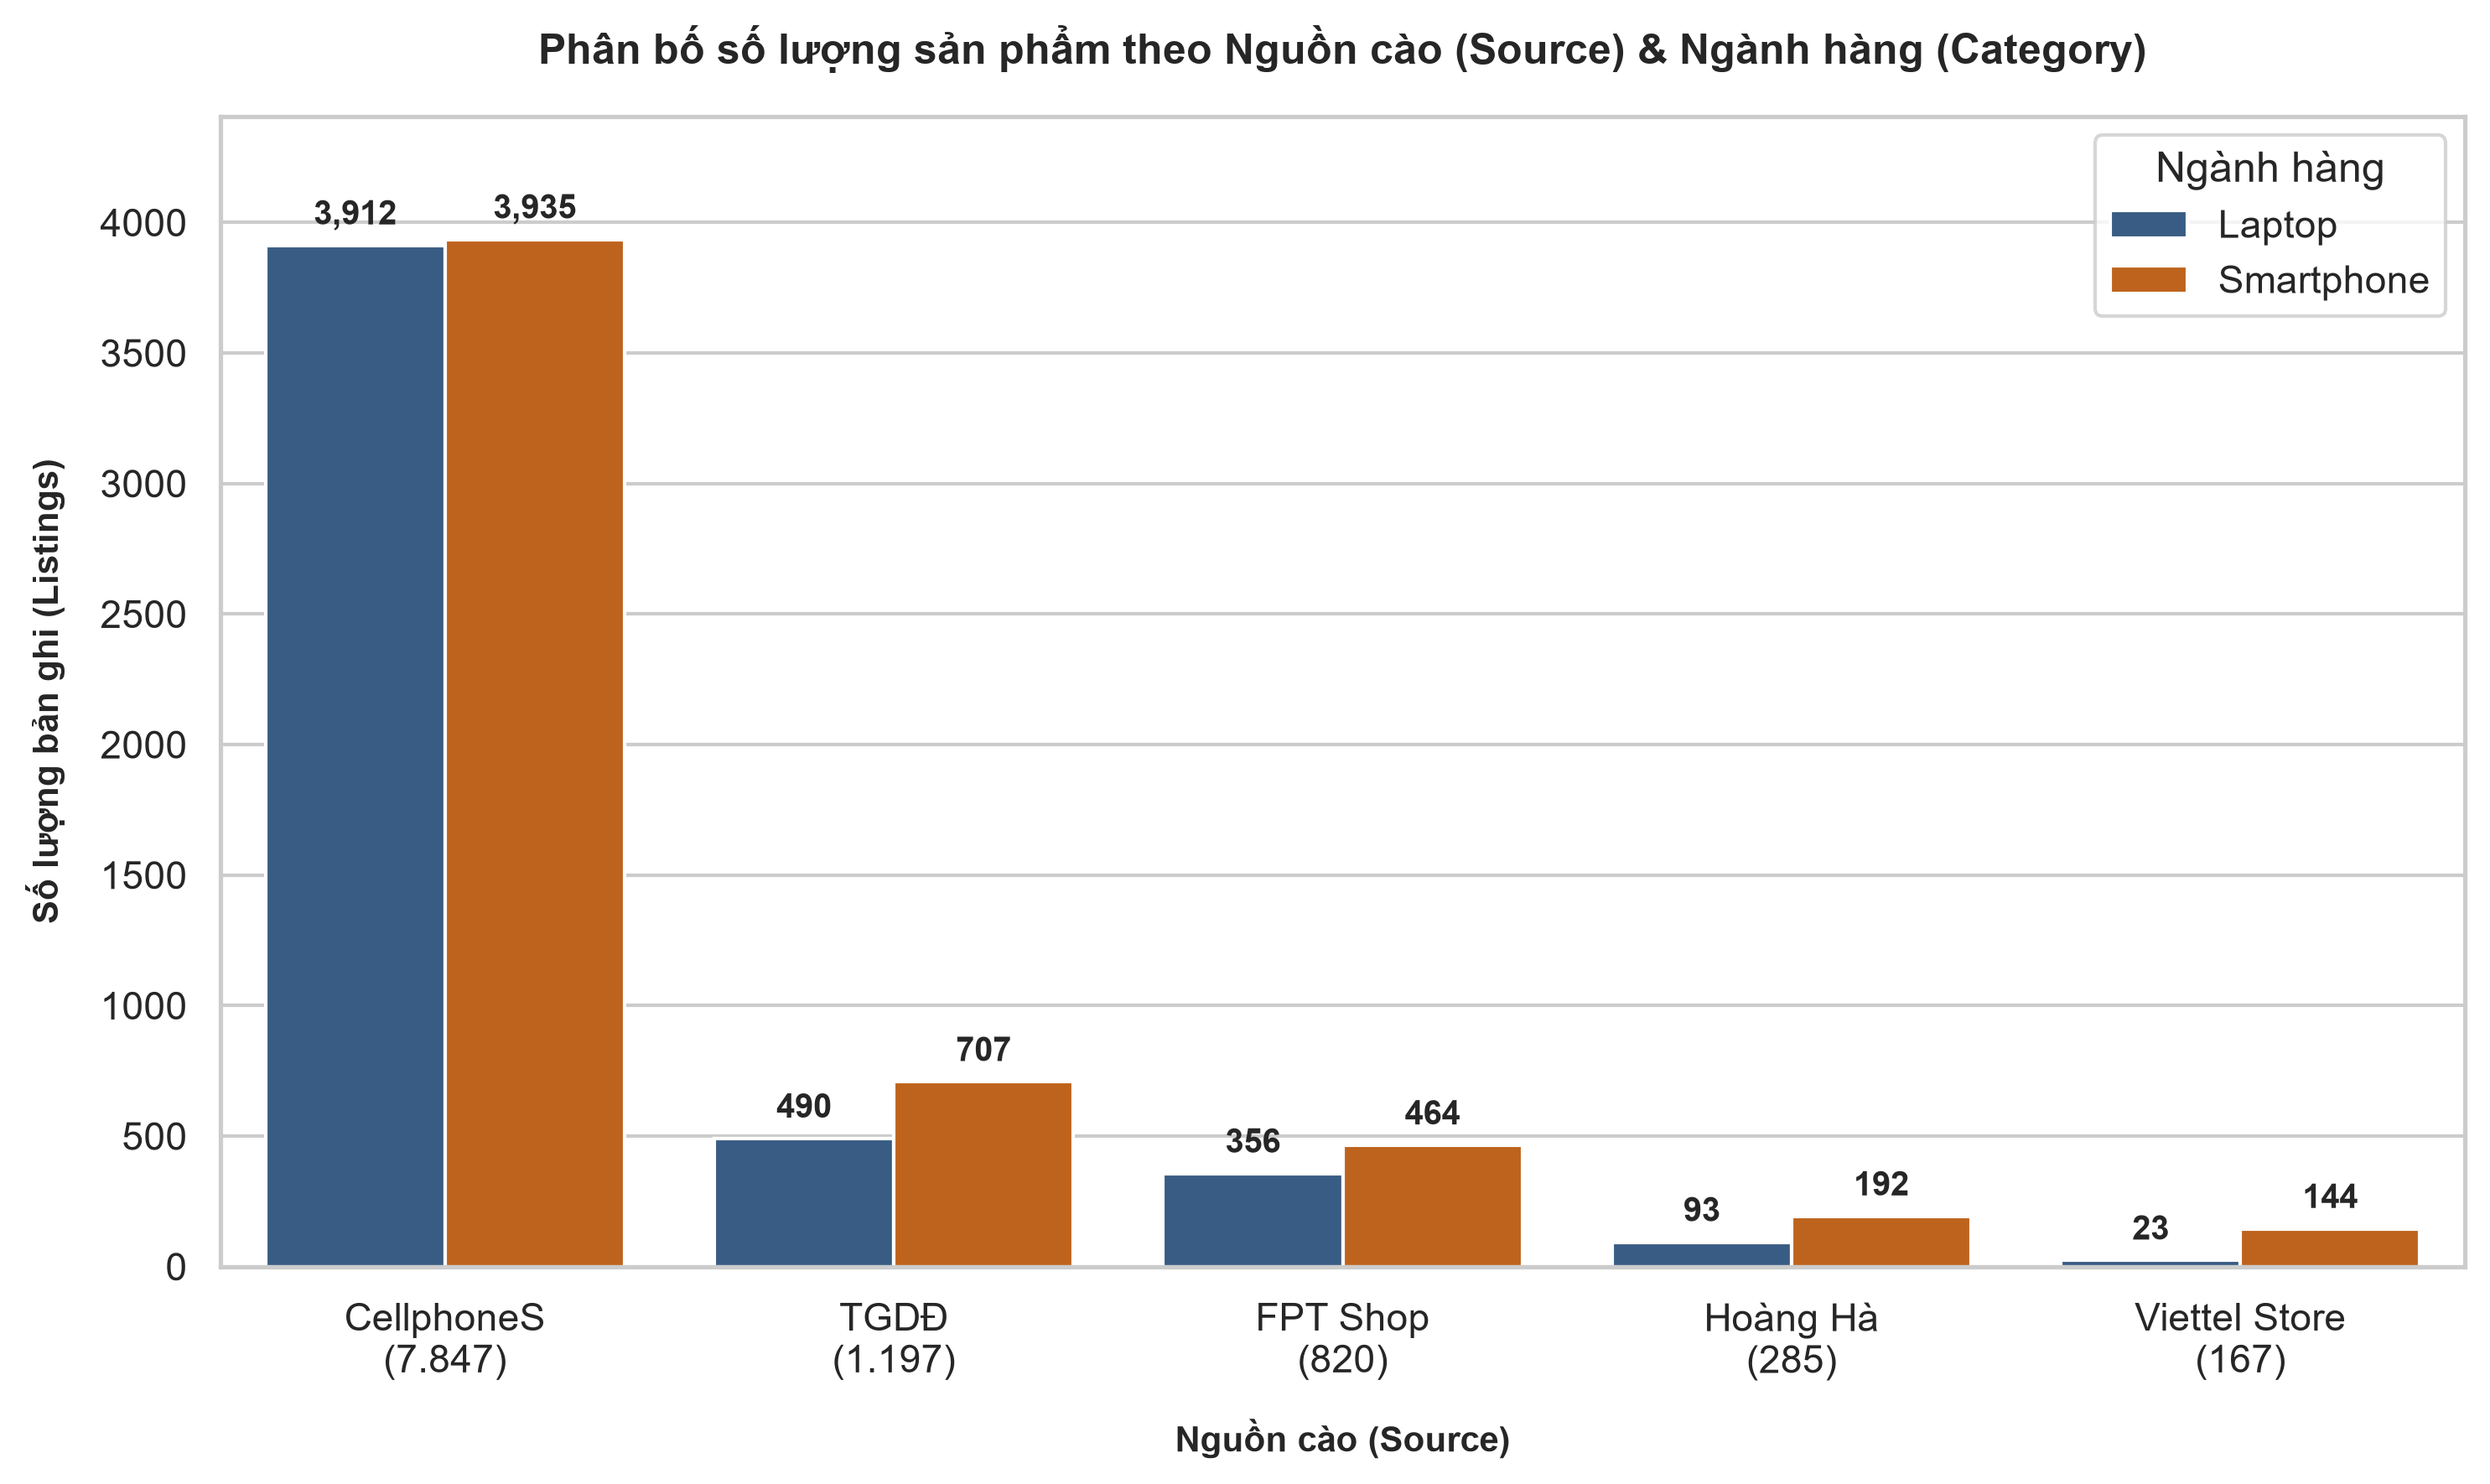

In [4]:
# Vẽ biểu đồ phân bố nguồn và danh mục (Fig 1.1A)
fig_path = "src/eda/outputs/figures/fig_1_1_source_category_distribution.png"
plot_source_category_distribution(df, fig_path)

# Hiển thị inline chuẩn 300 DPI
from IPython.display import Image, display
display(Image(fig_path))


## 3. Phân tích Thị phần Thương hiệu (Brand Market Share)

In [5]:
brand_dict = get_brand_market_share(df, top_n=10)

print("Top 10 Hãng Laptop:")
display(brand_dict["laptop"])

print("\nTop 10 Hãng Smartphone:")
display(brand_dict["smartphone"])

Top 10 Hãng Laptop:


,count,share_pct
ASUS,1164,23.88
Apple,961,19.72
Lenovo,740,15.18
HP,523,10.73
Dell,495,10.16
MSI,390,8.00
Acer,355,7.28
Gigabyte,68,1.40
Microsoft,56,1.15
LG,46,0.94



Top 10 Hãng Smartphone:


,count,share_pct
Samsung,975,17.92
Xiaomi,948,17.42
Apple,722,13.27
OPPO,493,9.06
Vivo,328,6.03
Realme,286,5.26
Honor,208,3.82
Nubia,189,3.47
Tecno,186,3.42
Nokia,183,3.36


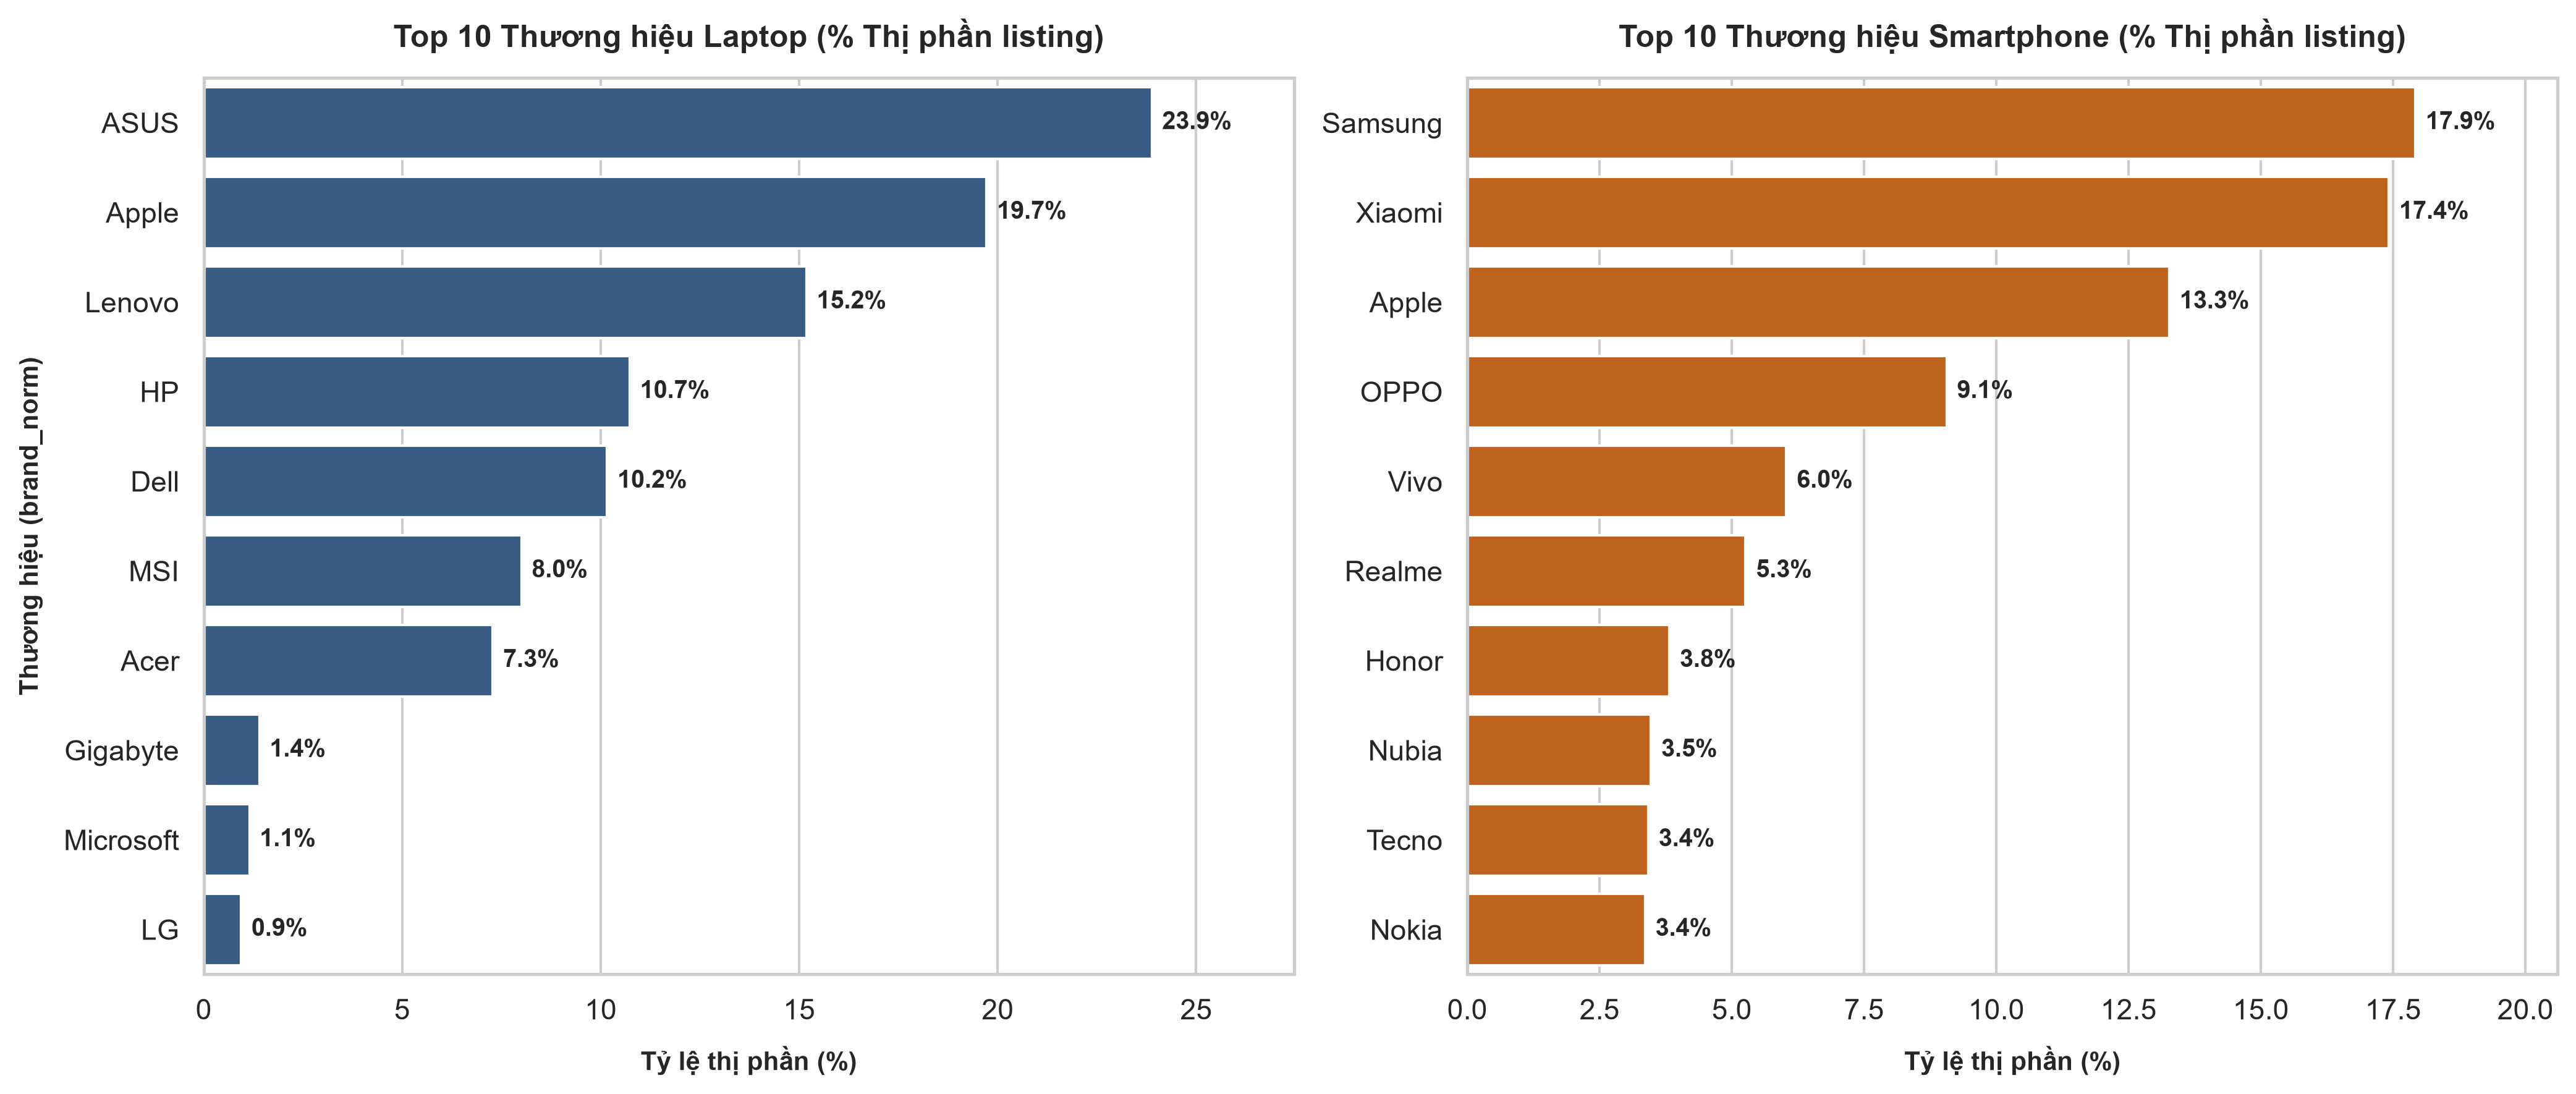

In [6]:
# Biểu đồ so sánh Top thương hiệu Laptop vs Smartphone (Fig 1.1B)
fig_brand_path = "src/eda/outputs/figures/fig_1_1_brand_market_share.png"
plot_brand_market_share_comparison(brand_dict, fig_brand_path)
display(Image(fig_brand_path))


## 4. Phân phối theo Nhà bán lẻ (seller_raw)

,count,share_pct,cumulative_pct
seller_raw,,,
CellphoneS,7847,76.07,76.07
Thế Giới Di Động,1197,11.60,87.67
FPT Shop,820,7.95,95.62
Hoàng Hà Mobile,285,2.76,98.38
Viettel Store,167,1.62,100.00


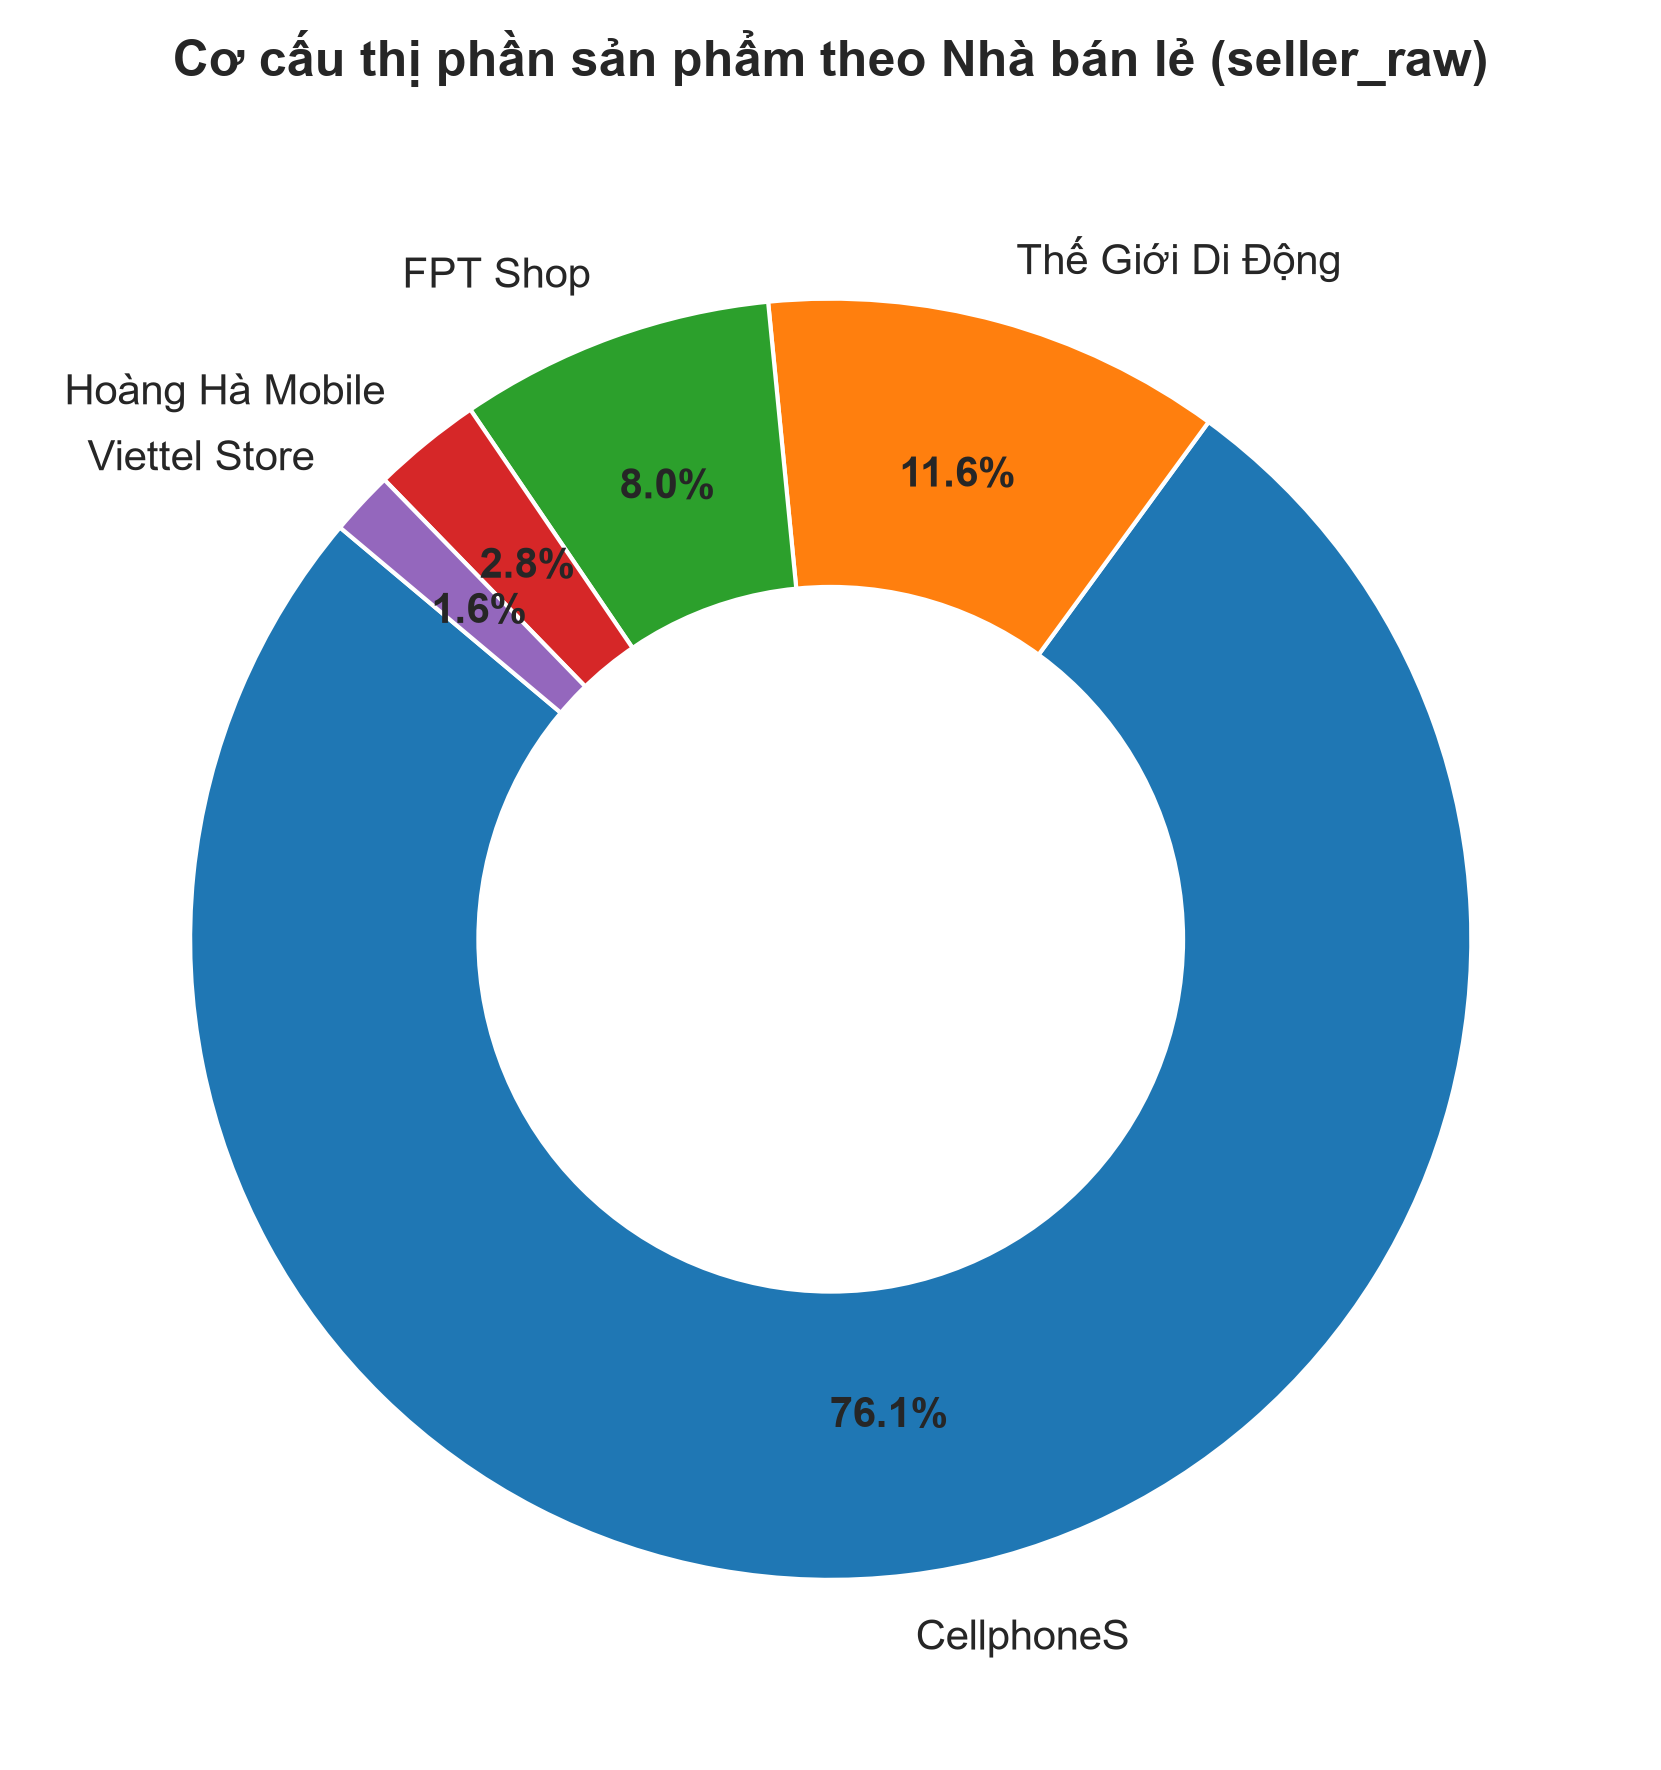

In [7]:
seller_df = get_seller_distribution(df)
display(seller_df)

# Biểu đồ thị phần nhà bán lẻ (Fig 1.1C)
fig_seller_path = "src/eda/outputs/figures/fig_1_1_seller_market_share.png"
plot_seller_share(seller_df, fig_seller_path)
display(Image(fig_seller_path))


## 5. Kết luận sơ bộ Nhiệm vụ 1.1

1. **Mất cân bằng nguồn cào (Source Asymmetry)**:
   * `cellphones` chiếm áp đảo với 76,07% tổng số listing (7.847 sản phẩm), tiếp theo là `tgdd` (11,60%) và `fptshop` (7,95%).
   * Khi phân tích các đặc trưng chi tiết (RAM, CPU, Pin) cần lưu ý xu hướng của CellphoneS có thể đại diện cho phần lớn dữ liệu.

2. **Cân bằng ngành hàng (Category Balance)**:
   * Tỷ lệ phân bố giữa hai danh mục khá đồng đều: **Smartphone** (5.442 mẫu - 52,75%) và **Laptop** (4.874 mẫu - 47,25%).

3. **Đặc trưng thị phần thương hiệu (Brand Concentration)**:
   * *Laptop*: Mức độ tập trung rất cao ở Top 5 thương hiệu: **ASUS (23,88%)**, **Apple (19,72%)**, **Lenovo (15,18%)**, **HP (10,73%)**, và **Dell (10,16%)** — chiếm tới gần 80% thị phần.
   * *Smartphone*: Cạnh tranh đa cực với 2 ông lớn dẫn đầu là **Samsung (17,92%)** và **Xiaomi (17,42%)**, kế tiếp là **Apple (13,27%)**, **OPPO (9,06%)**, **Vivo (6,03%)** và **Realme (5,26%)**.